# APY Dataset — Data Visualization

## Objective

This notebook presents the historical Area, Production, and Yield (APY) dataset through clear, interpretable, and presentation-ready visualizations.

The visualizations will focus on:
- Historical crop production trends
- Comparisons between major crops
- State-wise and district-wise production patterns
- Seasonal differences in agricultural production
- Data coverage and limitations affecting interpretation

## Data Source

The notebook uses the cleaned, flagged, long-format APY dataset covering agricultural years 2013–14 to 2024–25.

## Visualization Principles

- Exclude aggregate crop totals from individual-crop comparisons.
- Exclude `Season = Total` when aggregating seasonal records, to avoid double-counting.
- Preserve missing values rather than treating them as zero.
- Interpret observed production alongside data coverage.
- Avoid assigning physical units until the source's measurement definitions have been verified.

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

project_root = Path.cwd().parent

apy_path = (
    project_root
    / "data"
    / "processed"
    / "historical_food_grains_apy_long_2013-14_to_2024-25.csv"
)

apy_df = pd.read_csv(apy_path)

print("File exists:", apy_path.exists())
print("Dataset shape:", apy_df.shape)
print("Agricultural years:", sorted(apy_df["Year"].unique()))
print("Number of crops:", apy_df["Crop"].nunique())
print("Number of states:", apy_df["State"].nunique())

File exists: True
Dataset shape: (376272, 13)
Agricultural years: ['2013-14', '2014-15', '2015-16', '2016-17', '2017-18', '2018-19', '2019-20', '2020-21', '2021-22', '2022-23', '2023-24', '2024-25']
Number of crops: 19
Number of states: 34


Crops selected: ['Rice', 'Wheat', 'Maize', 'Gram', 'Bajra']


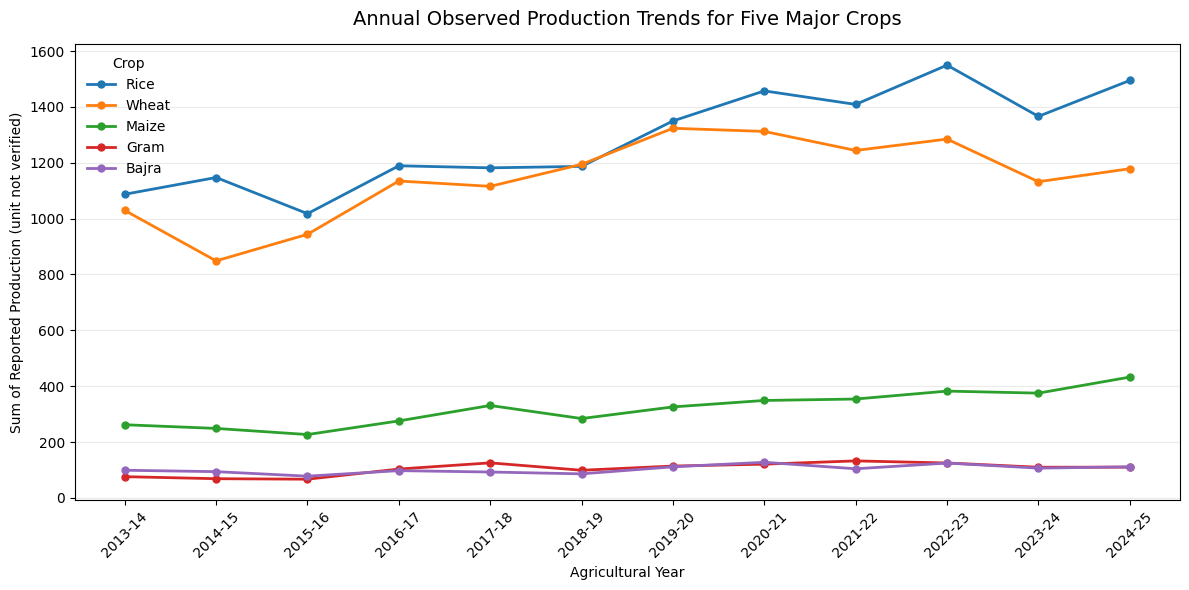

In [3]:
# Prepare individual-crop seasonal records for visualization.
visual_df = apy_df.loc[
    (apy_df["Crop_Category"] == "Individual Crop Candidate")
    & (apy_df["Season"] != "Total")
].copy()

# Aggregate observed production by agricultural year and crop.
annual_crop_production = (
    visual_df.groupby(["Year", "Crop"], as_index=False)
    .agg(
        Observed_Production=("Production", "sum"),
        Reported_Records=("Production", "count"),
        Total_Records=("Production", "size"),
    )
)

annual_crop_production["Production_Coverage_%"] = (
    annual_crop_production["Reported_Records"]
    / annual_crop_production["Total_Records"]
    * 100
).round(2)

# Select five crops with the largest observed sums across all years.
top_crops = (
    annual_crop_production.groupby("Crop")["Observed_Production"]
    .sum()
    .nlargest(5)
    .index.tolist()
)

print("Crops selected:", top_crops)

plot_df = annual_crop_production[
    annual_crop_production["Crop"].isin(top_crops)
].copy()

# Draw a presentation-ready line chart.
fig, ax = plt.subplots(figsize=(12, 6))

for crop in top_crops:
    crop_data = (
        plot_df[plot_df["Crop"] == crop]
        .set_index("Year")
        .reindex(sorted(apy_df["Year"].unique()))
        .rename_axis("Year")
        .reset_index()
    )

    ax.plot(
        crop_data["Year"],
        crop_data["Observed_Production"],
        marker="o",
        linewidth=2,
        markersize=5,
        label=crop,
    )

ax.set_title(
    "Annual Observed Production Trends for Five Major Crops",
    fontsize=14,
    pad=14,
)
ax.set_xlabel("Agricultural Year")
ax.set_ylabel("Sum of Reported Production (unit not verified)")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.25)
ax.legend(title="Crop", frameon=False)
fig.tight_layout()
plt.show()

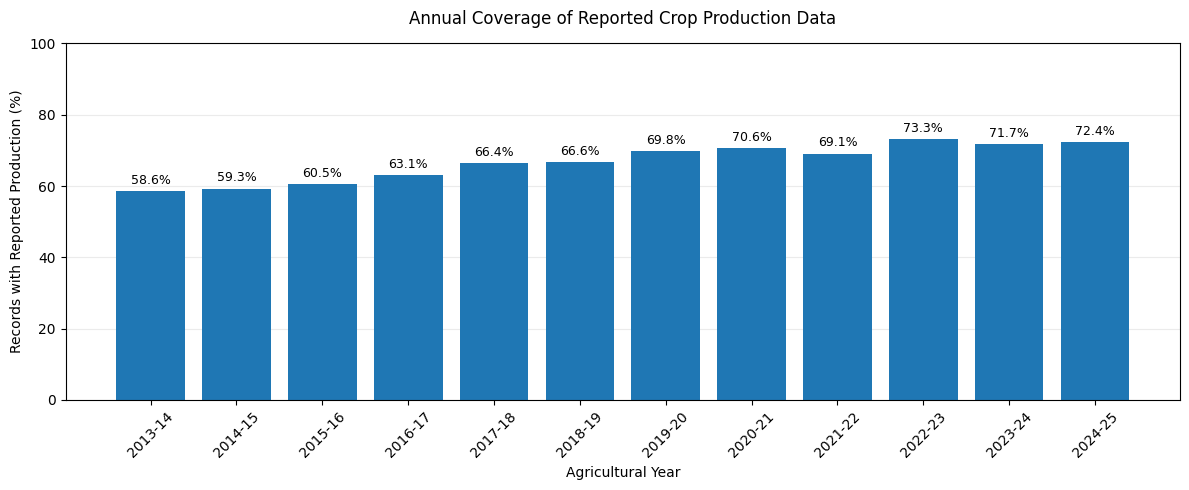

In [4]:

# Calculate annual production data coverage.
coverage_df = (
    visual_df.groupby("Year", as_index=False)
    .agg(
        Reported_Production=("Production", "count"),
        Total_Records=("Production", "size"),
    )
)

coverage_df["Coverage_%"] = (
    coverage_df["Reported_Production"]
    / coverage_df["Total_Records"]
    * 100
)

coverage_df = coverage_df.sort_values("Year")

# Plot annual data coverage.
fig, ax = plt.subplots(figsize=(12, 5))

bars = ax.bar(
    coverage_df["Year"],
    coverage_df["Coverage_%"],
)

ax.bar_label(
    bars,
    labels=[f"{value:.1f}%" for value in coverage_df["Coverage_%"]],
    padding=3,
    fontsize=9,
)

ax.set_title("Annual Coverage of Reported Crop Production Data", pad=14)
ax.set_xlabel("Agricultural Year")
ax.set_ylabel("Records with Reported Production (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()


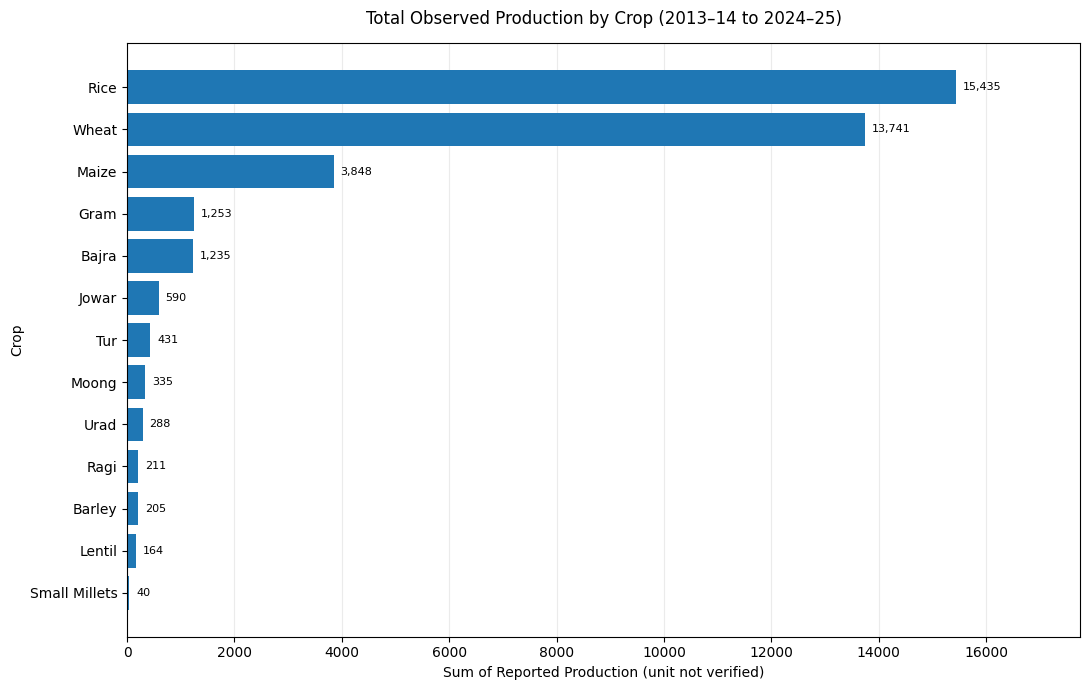

In [5]:

# Compare observed production totals across individual crops.
crop_production = (
    visual_df.groupby("Crop")["Production"]
    .sum(min_count=1)
    .dropna()
    .sort_values(ascending=True)
)

fig, ax = plt.subplots(figsize=(11, 7))

bars = ax.barh(
    crop_production.index,
    crop_production.values,
)

ax.set_title(
    "Total Observed Production by Crop (2013–14 to 2024–25)",
    pad=14,
)
ax.set_xlabel("Sum of Reported Production (unit not verified)")
ax.set_ylabel("Crop")
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

# Add value labels without overwhelming the chart.
for bar, value in zip(bars, crop_production.values):
    ax.annotate(
        f"{value:,.0f}",
        xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        va="center",
        fontsize=8,
    )

ax.margins(x=0.15)
fig.tight_layout()
plt.show()


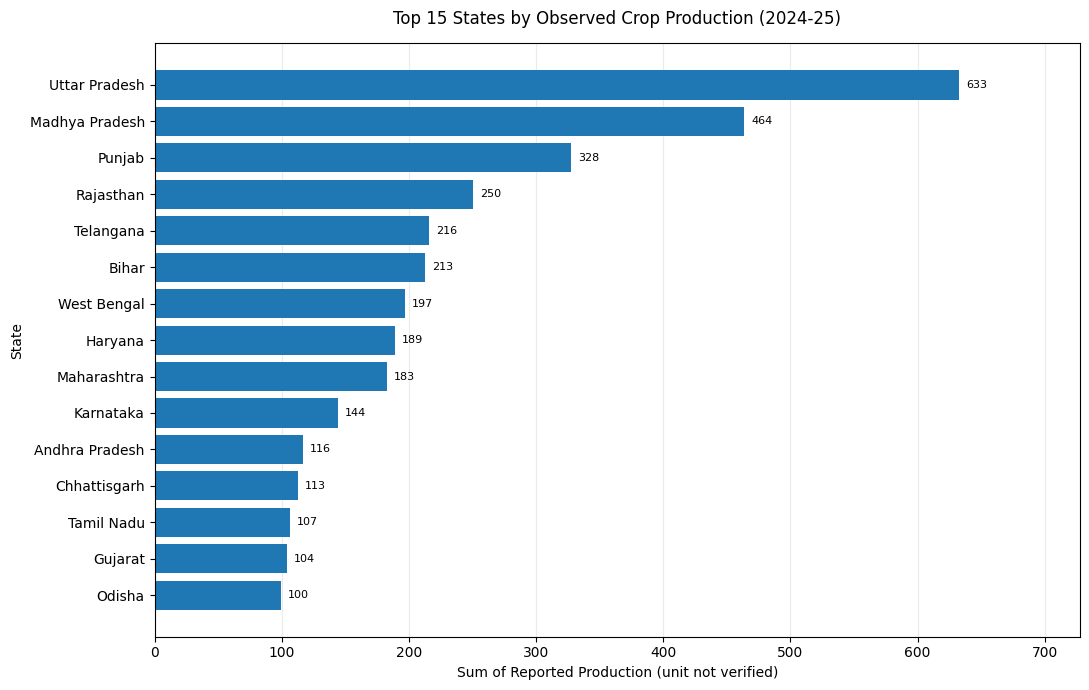

In [6]:

# Compare reported production across states for 2024–25.
latest_year = "2024-25"

state_production = (
    visual_df.loc[visual_df["Year"] == latest_year]
    .groupby("State")["Production"]
    .sum(min_count=1)
    .dropna()
    .sort_values(ascending=False)
)

top_states = state_production.head(15).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(11, 7))

bars = ax.barh(
    top_states.index,
    top_states.values,
)

ax.set_title(
    f"Top 15 States by Observed Crop Production ({latest_year})",
    pad=14,
)
ax.set_xlabel("Sum of Reported Production (unit not verified)")
ax.set_ylabel("State")
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

for bar, value in zip(bars, top_states.values):
    ax.annotate(
        f"{value:,.0f}",
        xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        va="center",
        fontsize=8,
    )

ax.margins(x=0.15)
fig.tight_layout()
plt.show()


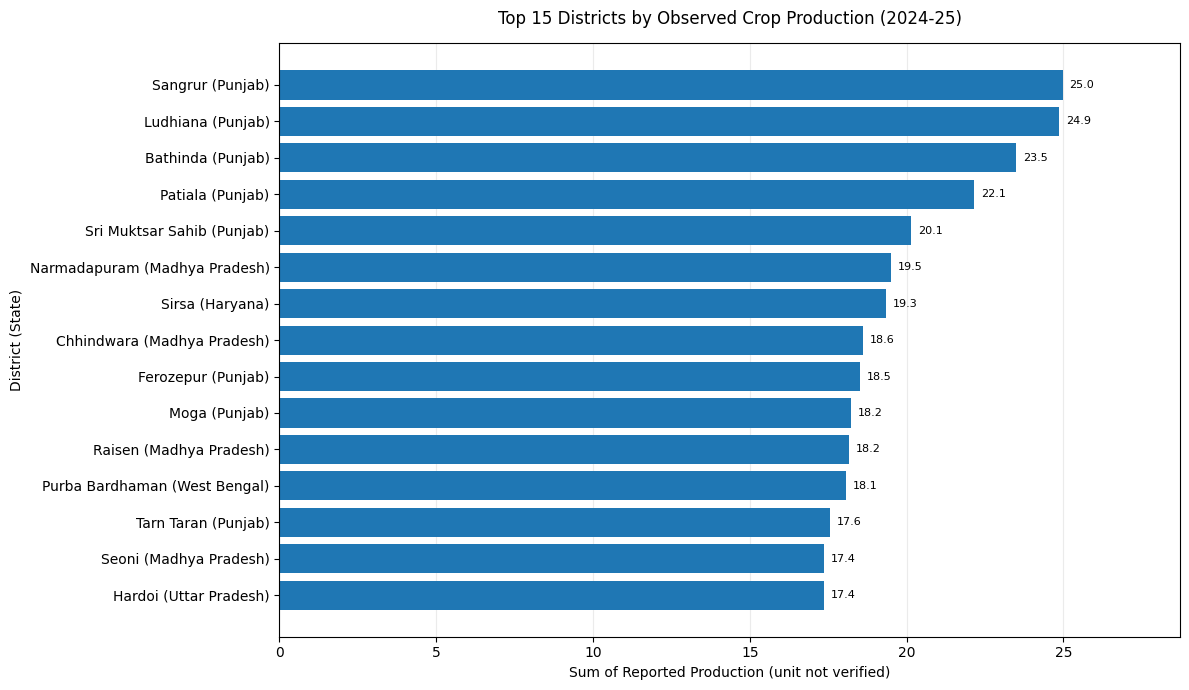

In [7]:

# Compare reported production across districts for 2024–25.
district_production = (
    visual_df.loc[visual_df["Year"] == latest_year]
    .groupby(["State", "District"])["Production"]
    .sum(min_count=1)
    .dropna()
    .sort_values(ascending=False)
)

top_districts = district_production.head(15).sort_values(ascending=True)

# Include state names to distinguish similarly named districts.
district_labels = [
    f"{district} ({state})"
    for state, district in top_districts.index
]

fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    district_labels,
    top_districts.values,
)

ax.set_title(
    f"Top 15 Districts by Observed Crop Production ({latest_year})",
    pad=14,
)
ax.set_xlabel("Sum of Reported Production (unit not verified)")
ax.set_ylabel("District (State)")
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

for bar, value in zip(bars, top_districts.values):
    ax.annotate(
        f"{value:,.1f}",
        xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        va="center",
        fontsize=8,
    )

ax.margins(x=0.15)
fig.tight_layout()
plt.show()


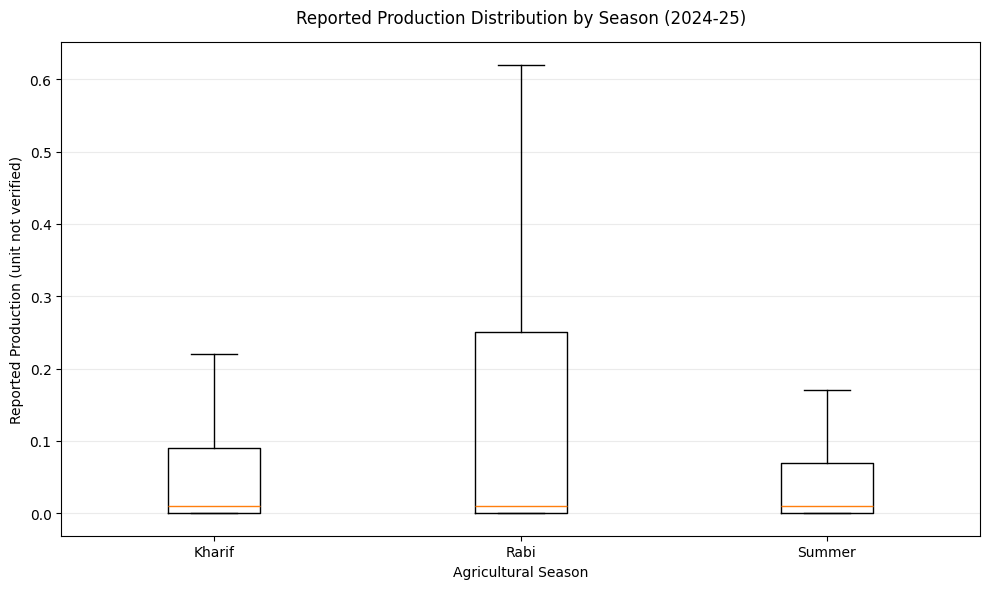

Records included by season:
Season
Kharif    4270
Rabi      2812
Summer    1155
Name: Production, dtype: int64


In [8]:

# Compare production distributions across agricultural seasons.
season_order = ["Kharif", "Rabi", "Summer"]

season_df = visual_df.loc[
    (visual_df["Year"] == latest_year)
    & (visual_df["Season"].isin(season_order))
    & (visual_df["Production"].notna())
    & (visual_df["Production"] >= 0)
].copy()

season_data = [
    season_df.loc[season_df["Season"] == season, "Production"].values
    for season in season_order
]

fig, ax = plt.subplots(figsize=(10, 6))

ax.boxplot(
    season_data,
    tick_labels=season_order,
    showfliers=False,
    patch_artist=False,
)

ax.set_title(
    f"Reported Production Distribution by Season ({latest_year})",
    pad=14,
)
ax.set_xlabel("Agricultural Season")
ax.set_ylabel("Reported Production (unit not verified)")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

print("Records included by season:")
print(season_df.groupby("Season")["Production"].count().reindex(season_order))


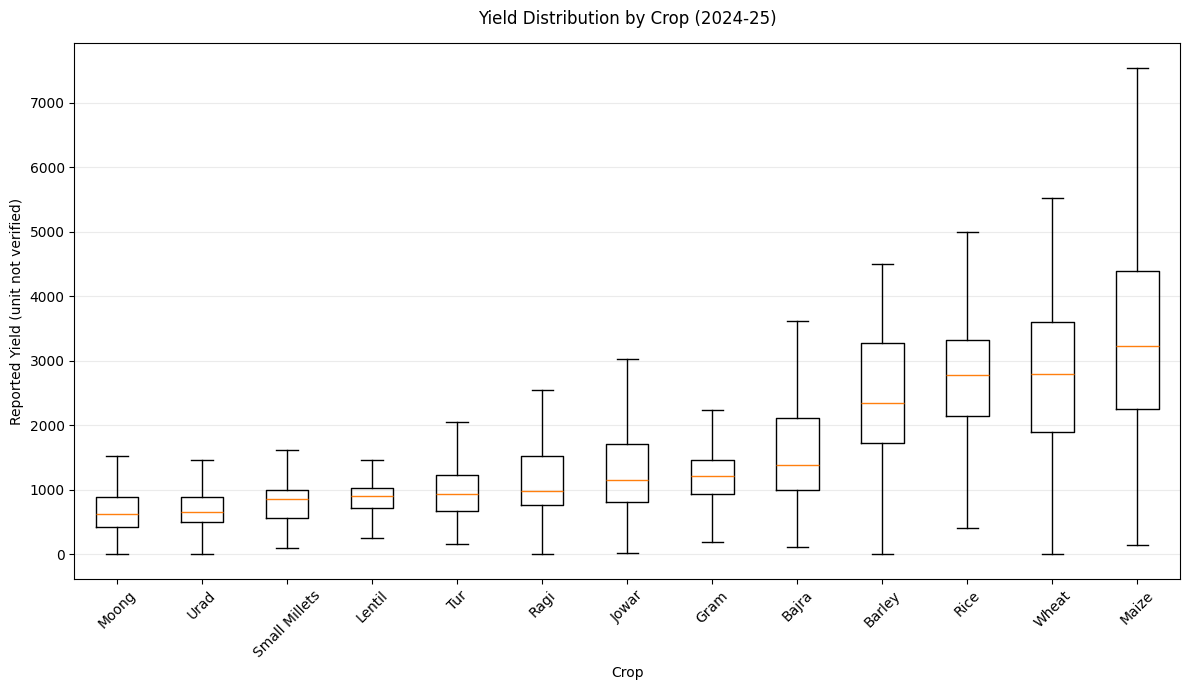

Valid non-negative yield records: 8237
Crops represented: 13


In [9]:

# Compare yield distributions across individual crops.
crop_order = (
    visual_df.loc[
        (visual_df["Year"] == latest_year)
        & visual_df["Yield"].notna()
        & (visual_df["Yield"] >= 0)
    ]
    .groupby("Crop")["Yield"]
    .median()
    .sort_values()
    .index
    .tolist()
)

yield_df = visual_df.loc[
    (visual_df["Year"] == latest_year)
    & visual_df["Crop"].isin(crop_order)
    & visual_df["Yield"].notna()
    & (visual_df["Yield"] >= 0)
].copy()

yield_data = [
    yield_df.loc[yield_df["Crop"] == crop, "Yield"].values
    for crop in crop_order
]

fig, ax = plt.subplots(figsize=(12, 7))

ax.boxplot(
    yield_data,
    tick_labels=crop_order,
    showfliers=False,
)

ax.set_title(
    f"Yield Distribution by Crop ({latest_year})",
    pad=14,
)
ax.set_xlabel("Crop")
ax.set_ylabel("Reported Yield (unit not verified)")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

print("Valid non-negative yield records:", len(yield_df))
print("Crops represented:", yield_df["Crop"].nunique())


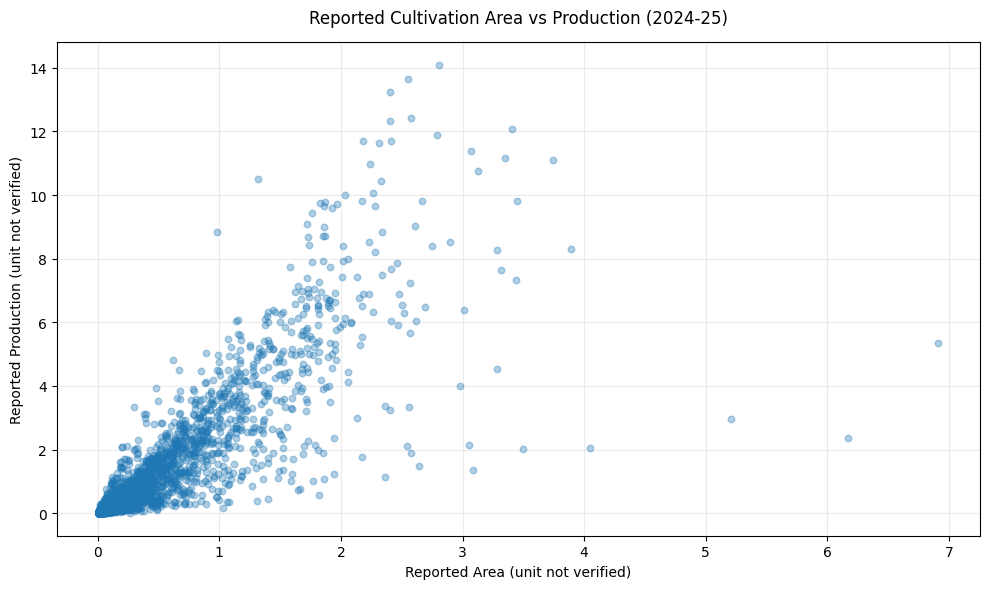

Records plotted: 4423
Pearson correlation: 0.864


In [10]:

# Examine the relationship between reported area and production.
scatter_df = visual_df.loc[
    (visual_df["Year"] == latest_year)
    & visual_df["Area"].notna()
    & visual_df["Production"].notna()
    & (visual_df["Area"] > 0)
    & (visual_df["Production"] >= 0)
].copy()

fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    scatter_df["Area"],
    scatter_df["Production"],
    alpha=0.35,
    s=22,
)

ax.set_title(
    f"Reported Cultivation Area vs Production ({latest_year})",
    pad=14,
)
ax.set_xlabel("Reported Area (unit not verified)")
ax.set_ylabel("Reported Production (unit not verified)")
ax.grid(alpha=0.25)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

if len(scatter_df) > 1:
    correlation = scatter_df["Area"].corr(scatter_df["Production"])
    print("Records plotted:", len(scatter_df))
    print(f"Pearson correlation: {correlation:.3f}")


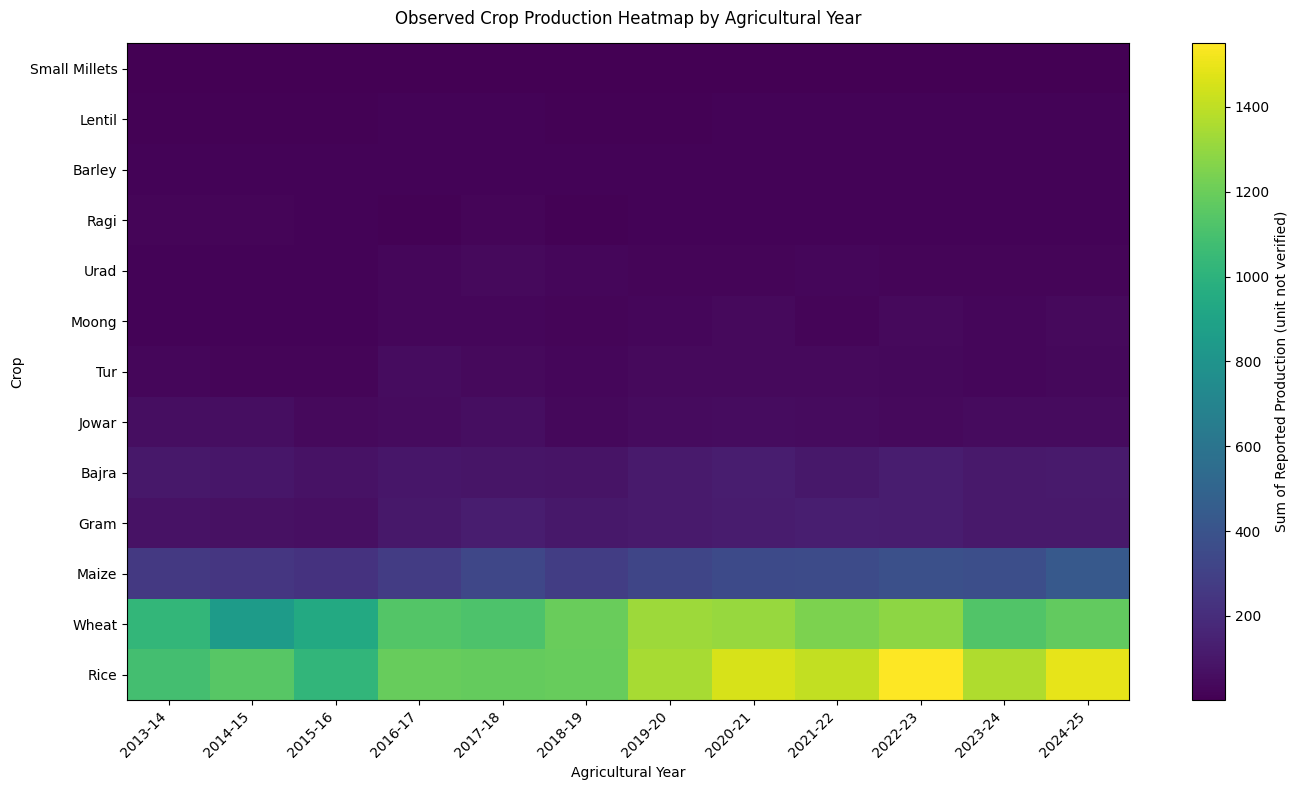

In [11]:

# Build a crop-by-year matrix of observed production.
heatmap_data = (
    visual_df.groupby(["Crop", "Year"])["Production"]
    .sum(min_count=1)
    .unstack("Year")
    .reindex(columns=sorted(visual_df["Year"].unique()))
)

# Order crops by their cumulative observed production.
heatmap_data = heatmap_data.loc[
    heatmap_data.sum(axis=1, min_count=1).sort_values().index
]

fig, ax = plt.subplots(figsize=(14, 8))

image = ax.imshow(
    heatmap_data,
    aspect="auto",
    interpolation="nearest",
)

ax.set_title("Observed Crop Production Heatmap by Agricultural Year", pad=14)
ax.set_xlabel("Agricultural Year")
ax.set_ylabel("Crop")
ax.set_xticks(range(len(heatmap_data.columns)))
ax.set_xticklabels(heatmap_data.columns, rotation=45, ha="right")
ax.set_yticks(range(len(heatmap_data.index)))
ax.set_yticklabels(heatmap_data.index)

colorbar = fig.colorbar(image, ax=ax)
colorbar.set_label("Sum of Reported Production (unit not verified)")

fig.tight_layout()
plt.show()


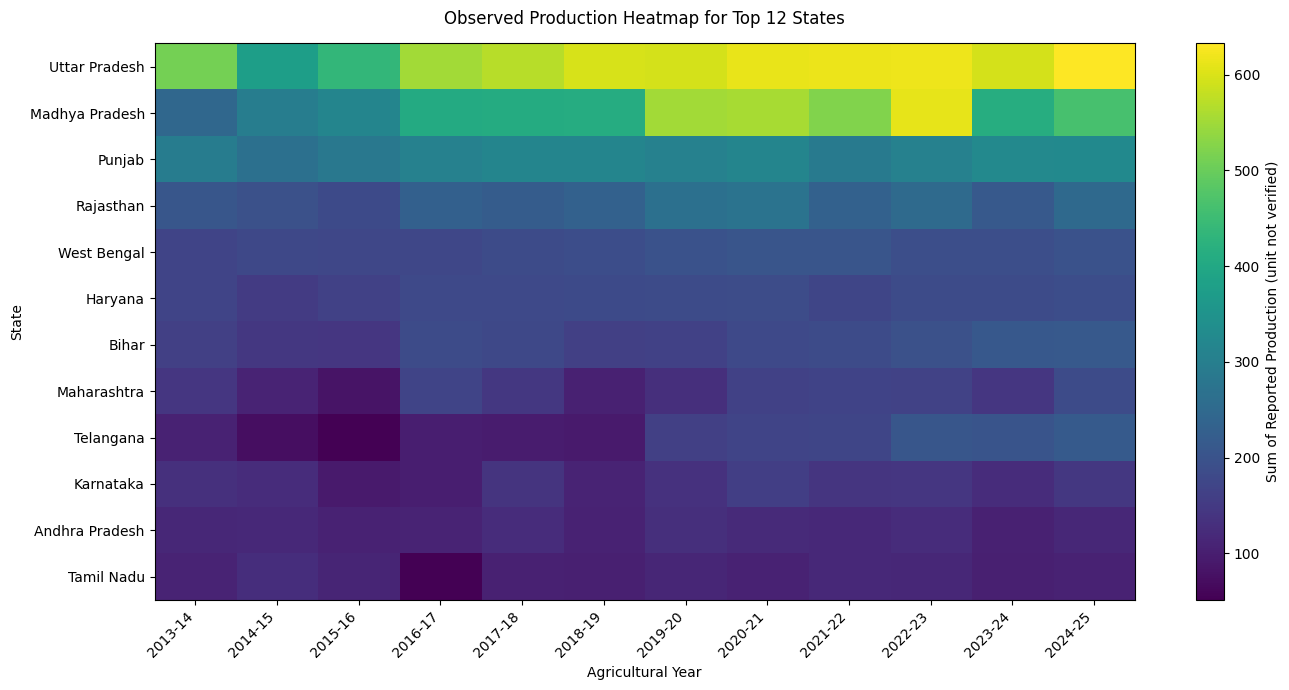

In [12]:

# Build a state-by-year production matrix.
state_year_production = (
    visual_df.groupby(["State", "Year"])["Production"]
    .sum(min_count=1)
    .unstack("Year")
    .reindex(columns=sorted(visual_df["Year"].unique()))
)

# Select the 12 states with the largest cumulative observed production.
top_12_states = (
    state_year_production.sum(axis=1, min_count=1)
    .nlargest(12)
    .index
)

state_heatmap = state_year_production.loc[top_12_states]

fig, ax = plt.subplots(figsize=(14, 7))

image = ax.imshow(
    state_heatmap,
    aspect="auto",
    interpolation="nearest",
)

ax.set_title("Observed Production Heatmap for Top 12 States", pad=14)
ax.set_xlabel("Agricultural Year")
ax.set_ylabel("State")
ax.set_xticks(range(len(state_heatmap.columns)))
ax.set_xticklabels(state_heatmap.columns, rotation=45, ha="right")
ax.set_yticks(range(len(state_heatmap.index)))
ax.set_yticklabels(state_heatmap.index)

colorbar = fig.colorbar(image, ax=ax)
colorbar.set_label("Sum of Reported Production (unit not verified)")

fig.tight_layout()
plt.show()


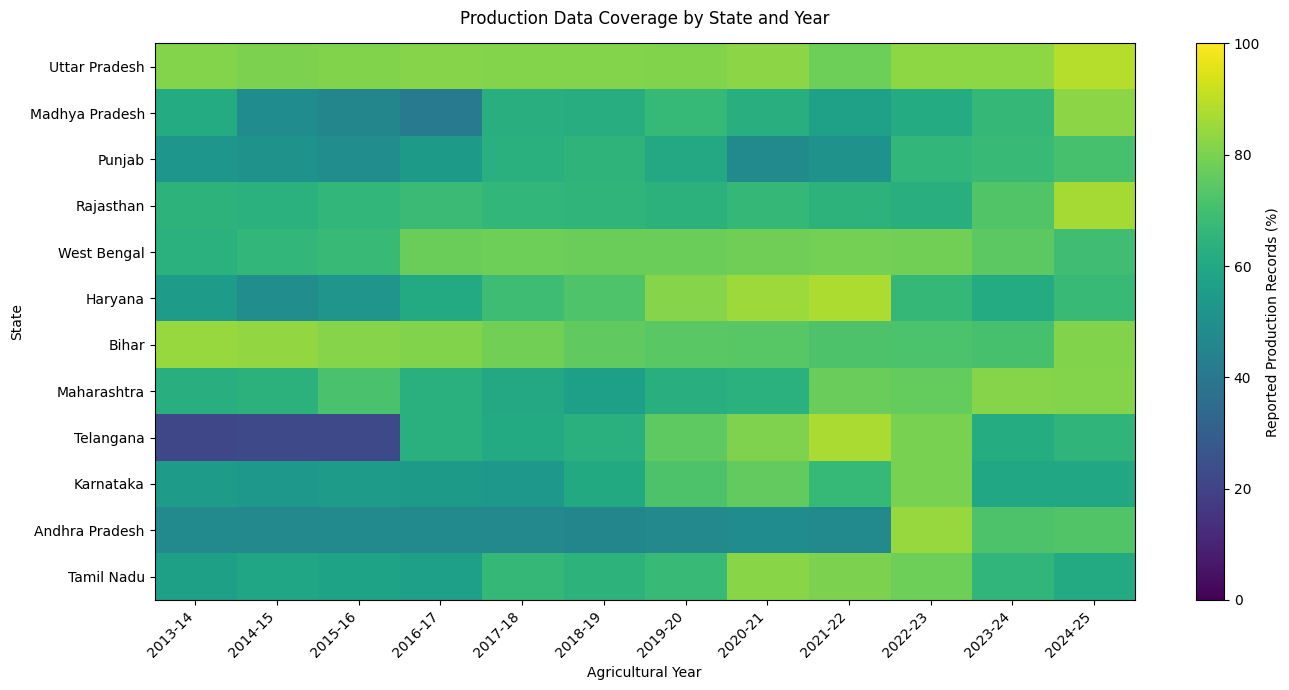

In [13]:

# Calculate production reporting coverage by state and year.
coverage_by_state_year = (
    visual_df.groupby(["State", "Year"])["Production"]
    .agg(
        Reported="count",
        Total="size",
    )
)

coverage_by_state_year["Coverage_%"] = (
    coverage_by_state_year["Reported"]
    / coverage_by_state_year["Total"]
    * 100
)

coverage_matrix = (
    coverage_by_state_year["Coverage_%"]
    .unstack("Year")
    .reindex(columns=sorted(visual_df["Year"].unique()))
)

# Use the same 12 states shown in the previous heatmap.
coverage_matrix = coverage_matrix.reindex(top_12_states)

fig, ax = plt.subplots(figsize=(14, 7))

image = ax.imshow(
    coverage_matrix,
    aspect="auto",
    interpolation="nearest",
    vmin=0,
    vmax=100,
)

ax.set_title("Production Data Coverage by State and Year", pad=14)
ax.set_xlabel("Agricultural Year")
ax.set_ylabel("State")
ax.set_xticks(range(len(coverage_matrix.columns)))
ax.set_xticklabels(coverage_matrix.columns, rotation=45, ha="right")
ax.set_yticks(range(len(coverage_matrix.index)))
ax.set_yticklabels(coverage_matrix.index)

colorbar = fig.colorbar(image, ax=ax)
colorbar.set_label("Reported Production Records (%)")

fig.tight_layout()
plt.show()


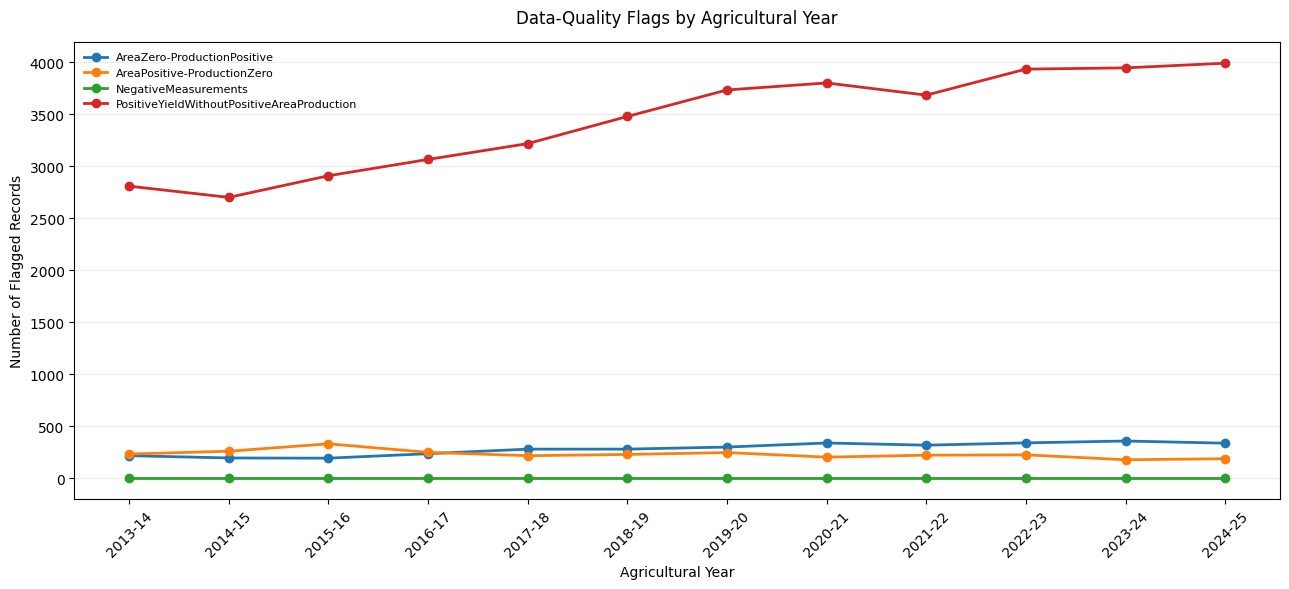

,QC_AreaZero-ProductionPositive,QC_AreaPositive-ProductionZero,QC_NegativeMeasurements,QC_PositiveYieldWithoutPositiveAreaProduction
Year,,,,
2013-14,216,232,0,2807
2014-15,194,259,0,2699
2015-16,192,330,0,2907
2016-17,235,248,0,3064
2017-18,279,216,0,3216
2018-19,279,228,0,3477
2019-20,299,246,0,3732
2020-21,338,202,0,3799
2021-22,317,221,0,3682


In [14]:

# Summarize data-quality flags by agricultural year.
qc_columns = [
    "QC_AreaZero-ProductionPositive",
    "QC_AreaPositive-ProductionZero",
    "QC_NegativeMeasurements",
    "QC_PositiveYieldWithoutPositiveAreaProduction",
]

qc_columns = [column for column in qc_columns if column in apy_df.columns]

qc_df = apy_df.loc[
    (apy_df["Crop_Category"] == "Individual Crop Candidate")
    & (apy_df["Season"] != "Total")
].copy()

qc_summary = (
    qc_df.groupby("Year")[qc_columns]
    .sum()
    .reindex(sorted(qc_df["Year"].unique()))
)

fig, ax = plt.subplots(figsize=(13, 6))

for column in qc_columns:
    ax.plot(
        qc_summary.index,
        qc_summary[column],
        marker="o",
        linewidth=2,
        label=column.replace("QC_", "").replace("_", " "),
    )

ax.set_title("Data-Quality Flags by Agricultural Year", pad=14)
ax.set_xlabel("Agricultural Year")
ax.set_ylabel("Number of Flagged Records")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=8)

fig.tight_layout()
plt.show()

display(qc_summary)


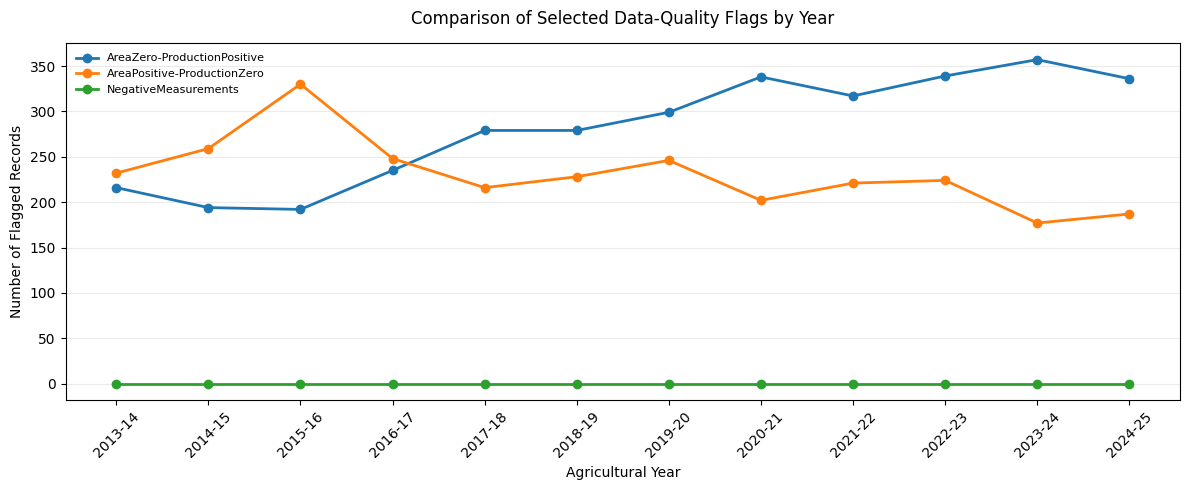

In [15]:

# Compare the smaller data-quality flags without the dominant series.
minor_qc_columns = [
    "QC_AreaZero-ProductionPositive",
    "QC_AreaPositive-ProductionZero",
    "QC_NegativeMeasurements",
]

fig, ax = plt.subplots(figsize=(12, 5))

for column in minor_qc_columns:
    ax.plot(
        qc_summary.index,
        qc_summary[column],
        marker="o",
        linewidth=2,
        label=column.replace("QC_", "").replace("_", " "),
    )

ax.set_title("Comparison of Selected Data-Quality Flags by Year", pad=14)
ax.set_xlabel("Agricultural Year")
ax.set_ylabel("Number of Flagged Records")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=8)

fig.tight_layout()
plt.show()


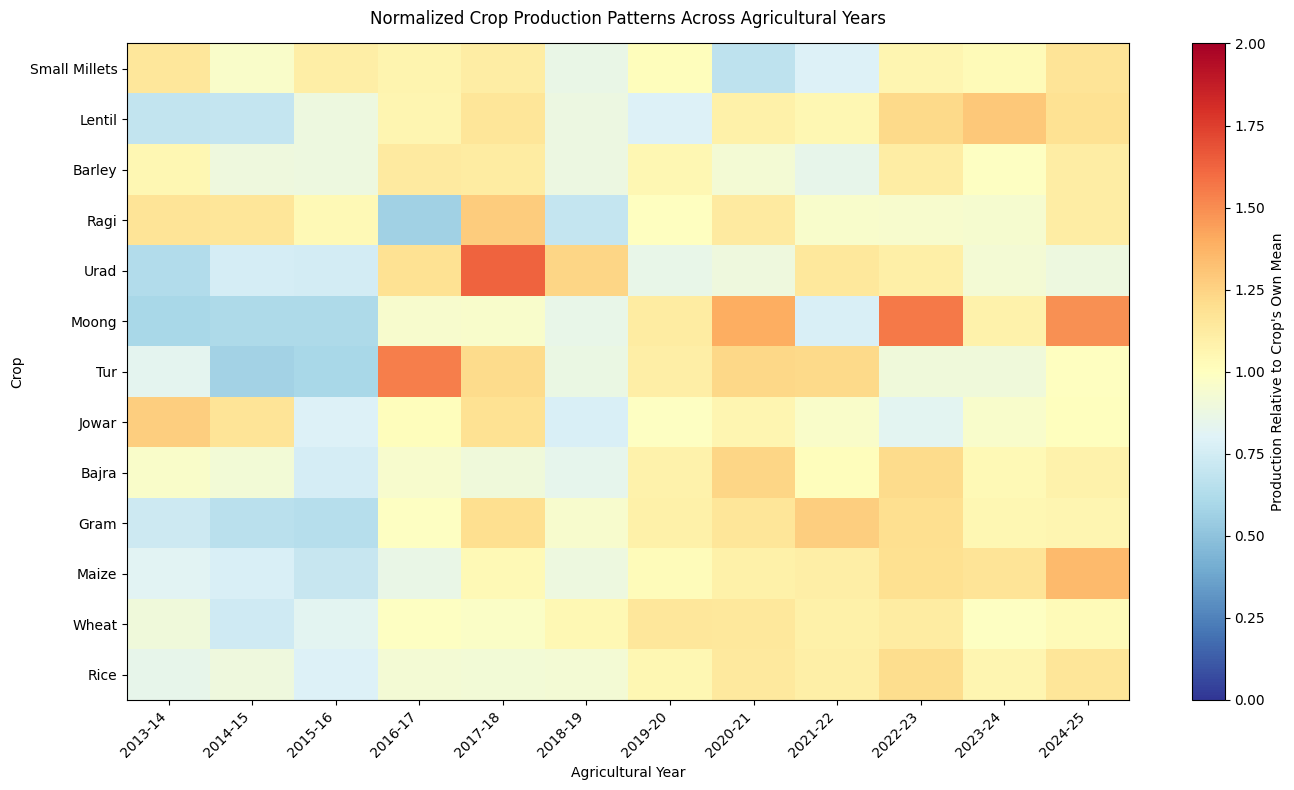

In [16]:

# Calculate annual observed production for each individual crop.
crop_year_production = (
    visual_df.groupby(["Crop", "Year"])["Production"]
    .sum(min_count=1)
    .unstack("Year")
    .reindex(columns=sorted(visual_df["Year"].unique()))
)

# Normalize each crop relative to its own mean production.
# Values above 1 indicate above-average observed production;
# values below 1 indicate below-average observed production.
crop_mean = crop_year_production.mean(axis=1)

normalized_production = crop_year_production.div(
    crop_mean.replace(0, np.nan),
    axis=0,
)

# Keep the same crop ordering as the original heatmap.
normalized_production = normalized_production.reindex(
    heatmap_data.index
)

fig, ax = plt.subplots(figsize=(14, 8))

image = ax.imshow(
    normalized_production,
    aspect="auto",
    interpolation="nearest",
    cmap="RdYlBu_r",
    vmin=0,
    vmax=2,
)

ax.set_title(
    "Normalized Crop Production Patterns Across Agricultural Years",
    pad=14,
)
ax.set_xlabel("Agricultural Year")
ax.set_ylabel("Crop")

ax.set_xticks(range(len(normalized_production.columns)))
ax.set_xticklabels(
    normalized_production.columns,
    rotation=45,
    ha="right",
)
ax.set_yticks(range(len(normalized_production.index)))
ax.set_yticklabels(normalized_production.index)

colorbar = fig.colorbar(image, ax=ax)
colorbar.set_label("Production Relative to Crop's Own Mean")

fig.tight_layout()
plt.show()


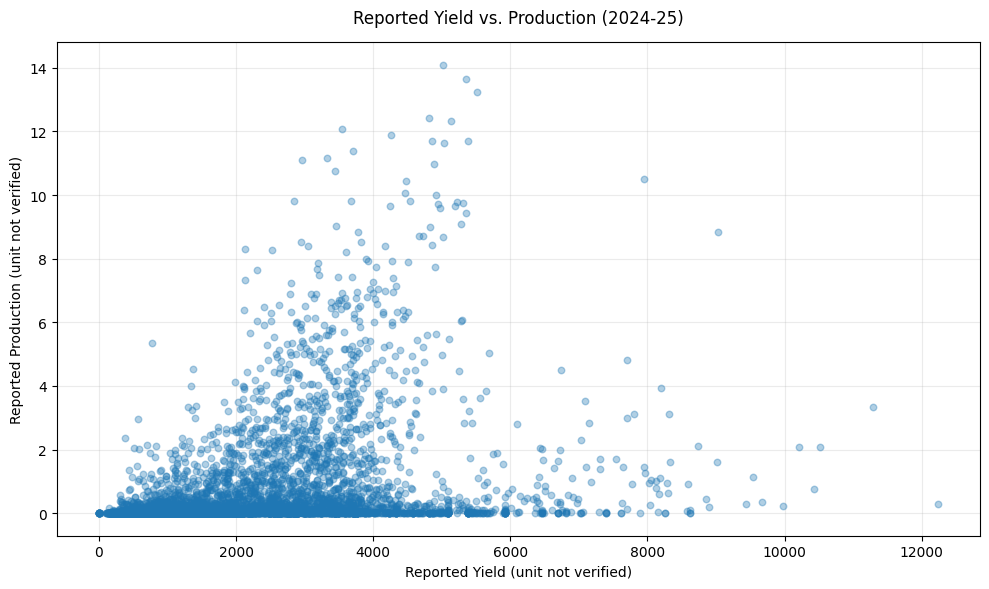

Records plotted: 8237
Pearson correlation: 0.368


In [17]:

# Examine the relationship between reported production and yield.
production_yield_df = visual_df.loc[
    (visual_df["Year"] == latest_year)
    & visual_df["Production"].notna()
    & visual_df["Yield"].notna()
    & (visual_df["Production"] >= 0)
    & (visual_df["Yield"] >= 0)
].copy()

fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    production_yield_df["Yield"],
    production_yield_df["Production"],
    alpha=0.35,
    s=22,
)

ax.set_title(
    f"Reported Yield vs. Production ({latest_year})",
    pad=14,
)
ax.set_xlabel("Reported Yield (unit not verified)")
ax.set_ylabel("Reported Production (unit not verified)")
ax.grid(alpha=0.25)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

print("Records plotted:", len(production_yield_df))

if len(production_yield_df) > 1:
    correlation = production_yield_df["Yield"].corr(
        production_yield_df["Production"]
    )
    print(f"Pearson correlation: {correlation:.3f}")


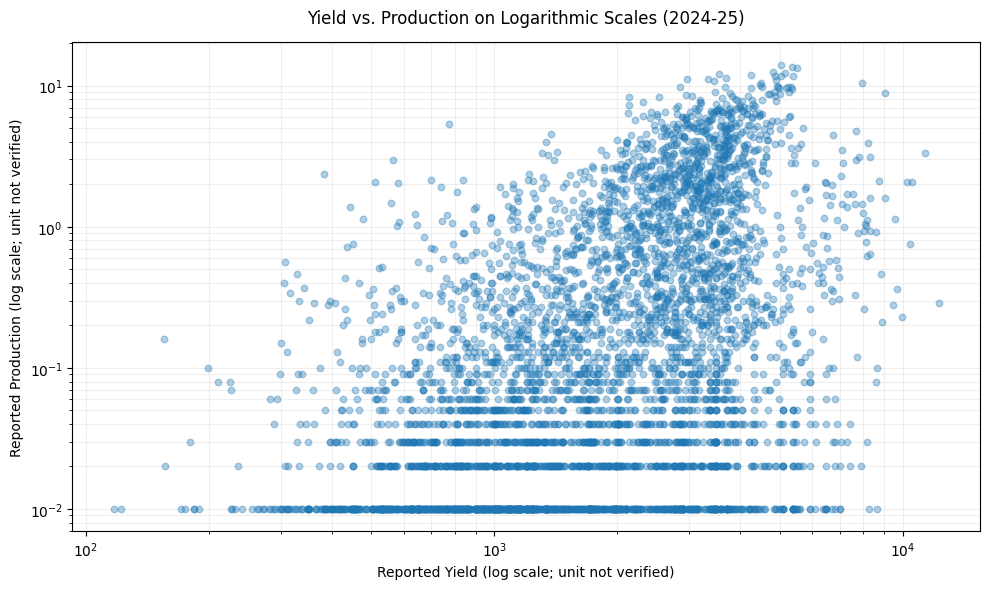

Positive-value records plotted: 4572


In [18]:

# Inspect production and yield using logarithmic axes.
# Log scales require strictly positive values.
log_scatter_df = production_yield_df.loc[
    (production_yield_df["Yield"] > 0)
    & (production_yield_df["Production"] > 0)
].copy()

fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    log_scatter_df["Yield"],
    log_scatter_df["Production"],
    alpha=0.35,
    s=22,
)

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_title(
    f"Yield vs. Production on Logarithmic Scales ({latest_year})",
    pad=14,
)
ax.set_xlabel("Reported Yield (log scale; unit not verified)")
ax.set_ylabel("Reported Production (log scale; unit not verified)")
ax.grid(True, which="both", alpha=0.2)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

print("Positive-value records plotted:", len(log_scatter_df))


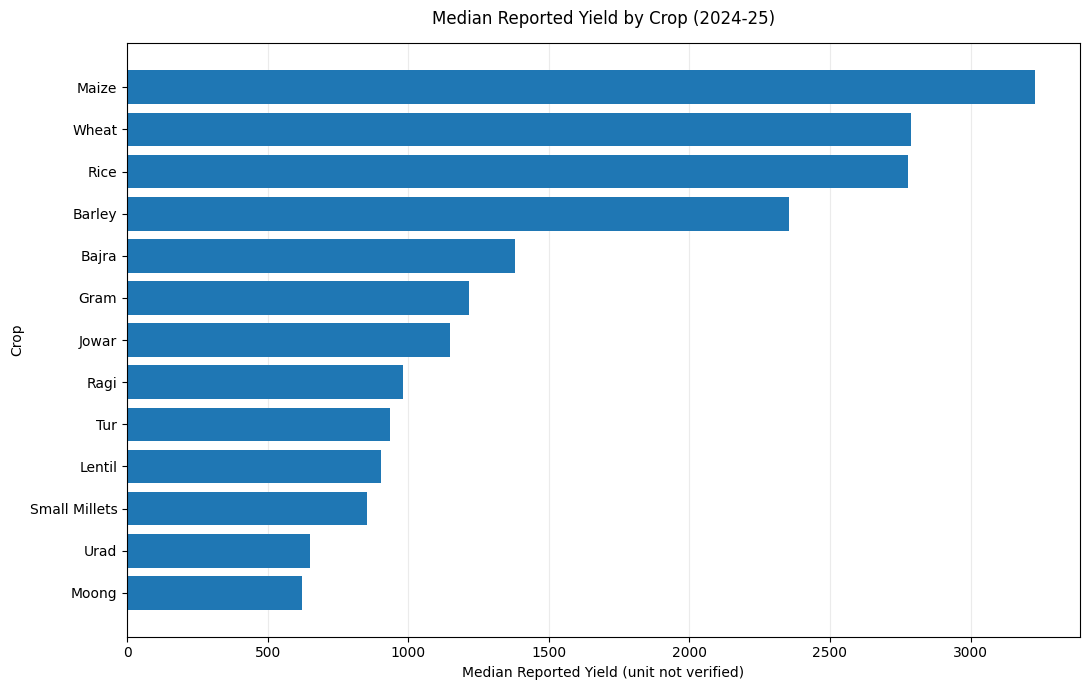

,Median_Yield,Valid_Records
Crop,,
Moong,624.0,1039
Urad,652.0,919
Small Millets,853.0,341
Lentil,902.0,337
Tur,935.5,520
Ragi,981.0,290
Jowar,1147.0,553
Gram,1216.0,507
Bajra,1380.0,468


In [19]:

# Compare median reported yield across crops for the latest agricultural year.
latest_yield_df = visual_df.loc[
    (visual_df["Year"] == latest_year)
    & visual_df["Yield"].notna()
    & (visual_df["Yield"] >= 0)
].copy()

crop_yield_summary = (
    latest_yield_df.groupby("Crop")
    .agg(
        Median_Yield=("Yield", "median"),
        Valid_Records=("Yield", "count"),
    )
    .sort_values("Median_Yield", ascending=True)
)

fig, ax = plt.subplots(figsize=(11, 7))

bars = ax.barh(
    crop_yield_summary.index,
    crop_yield_summary["Median_Yield"],
)

ax.set_title(
    f"Median Reported Yield by Crop ({latest_year})",
    pad=14,
)
ax.set_xlabel("Median Reported Yield (unit not verified)")
ax.set_ylabel("Crop")
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

display(crop_yield_summary)


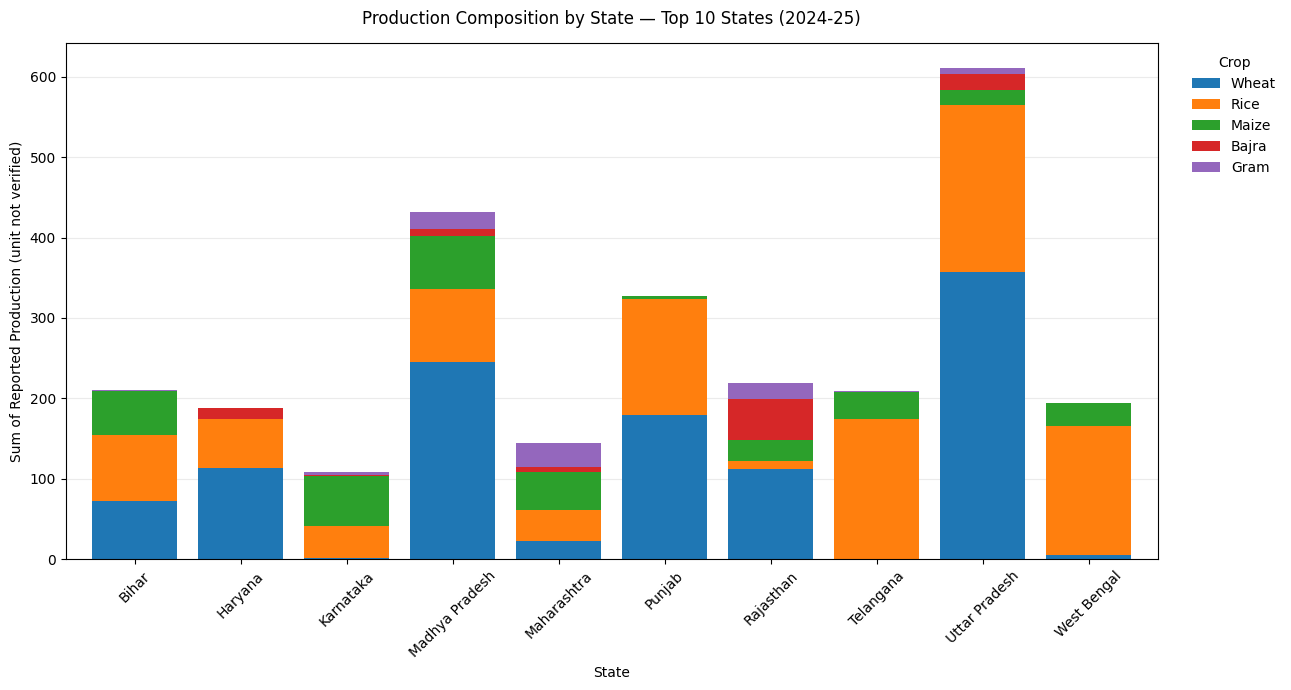

In [20]:

# Compare crop composition across the ten states with the highest
# observed production in the latest agricultural year.
latest_state_crop = visual_df.loc[
    (visual_df["Year"] == latest_year)
    & visual_df["Production"].notna()
].copy()

state_totals = (
    latest_state_crop.groupby("State")["Production"]
    .sum(min_count=1)
    .sort_values(ascending=False)
)

top_states = state_totals.head(10).index

state_crop_production = (
    latest_state_crop[latest_state_crop["State"].isin(top_states)]
    .groupby(["State", "Crop"])["Production"]
    .sum(min_count=1)
    .unstack("Crop")
    .fillna(0)
)

# Keep only the five crops with the largest observed production
# across the selected states.
top_state_crops = (
    state_crop_production.sum()
    .sort_values(ascending=False)
    .head(5)
    .index
)

composition_df = state_crop_production[top_state_crops]

ax = composition_df.plot(
    kind="bar",
    stacked=True,
    figsize=(13, 7),
    width=0.8,
)

ax.set_title(
    f"Production Composition by State — Top 10 States ({latest_year})",
    pad=14,
)
ax.set_xlabel("State")
ax.set_ylabel("Sum of Reported Production (unit not verified)")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.legend(title="Crop", frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")

fig = ax.get_figure()
fig.tight_layout()
plt.show()


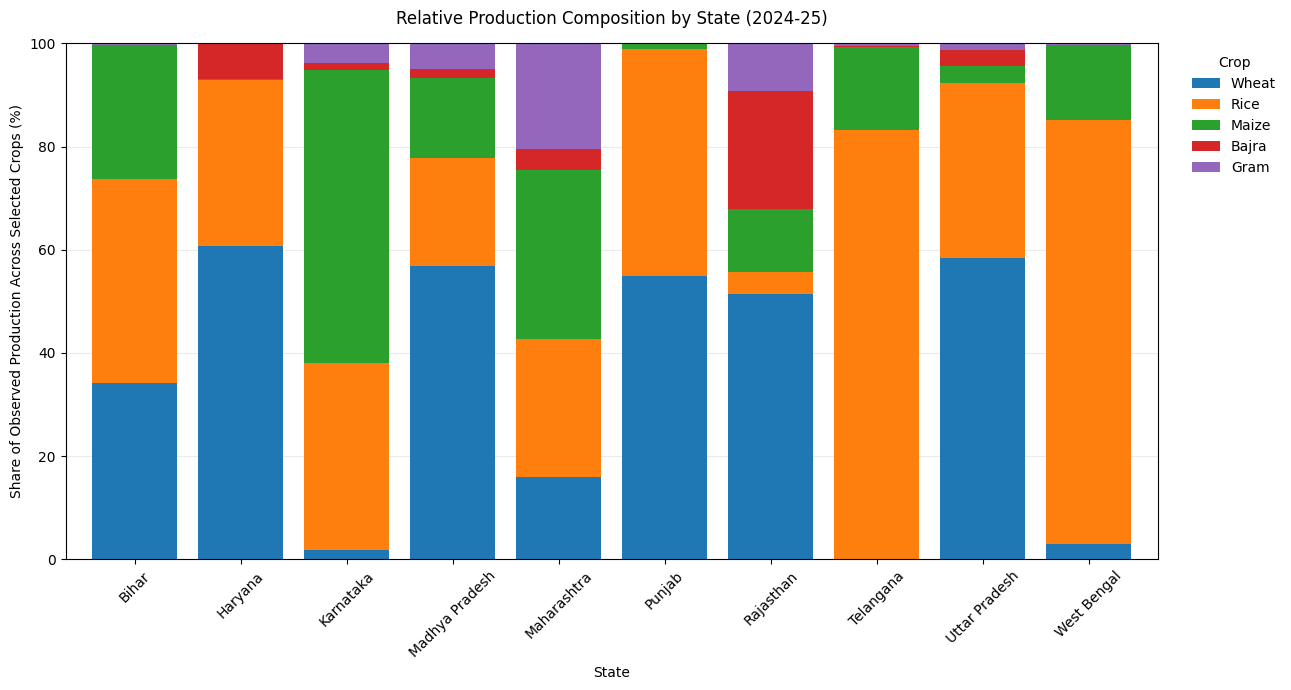

In [21]:

# Convert observed production into within-state percentages.
# Percentages describe only the five crops selected above.
state_crop_percent = (
    composition_df.div(composition_df.sum(axis=1).replace(0, np.nan), axis=0)
    * 100
)

ax = state_crop_percent.plot(
    kind="bar",
    stacked=True,
    figsize=(13, 7),
    width=0.8,
)

ax.set_title(
    f"Relative Production Composition by State ({latest_year})",
    pad=14,
)
ax.set_xlabel("State")
ax.set_ylabel("Share of Observed Production Across Selected Crops (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.legend(
    title="Crop",
    frameon=False,
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

fig = ax.get_figure()
fig.tight_layout()
plt.show()


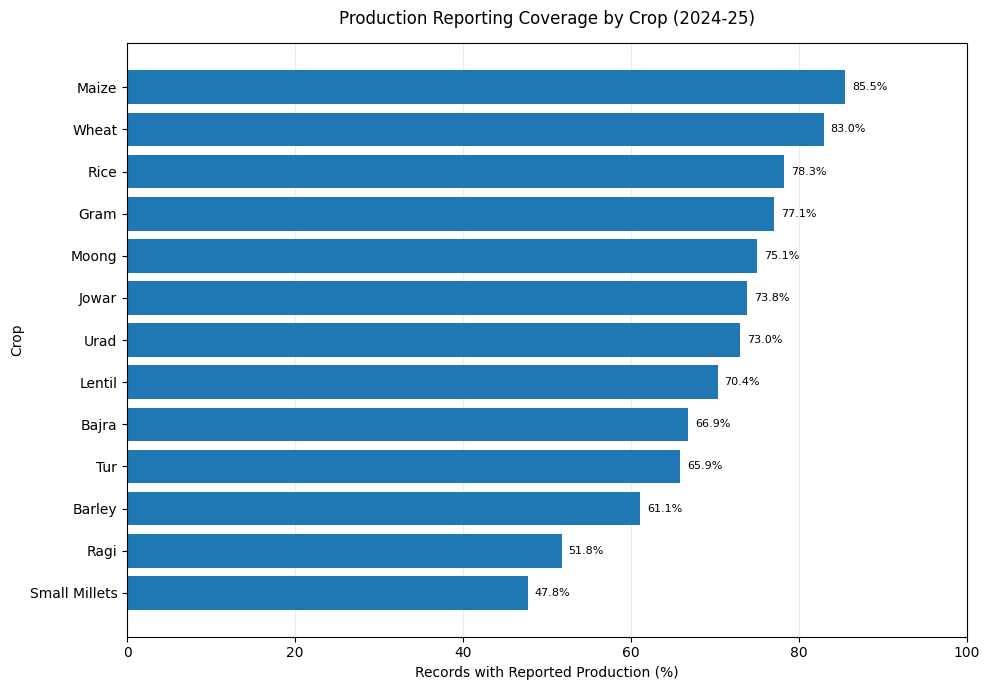

,Total_Records,Reported_Production_Records,Coverage_%
Crop,,,
Small Millets,714,341,47.76
Ragi,560,290,51.79
Barley,440,269,61.14
Tur,789,520,65.91
Bajra,700,468,66.86
Lentil,479,337,70.35
Urad,1259,919,72.99
Jowar,749,553,73.83
Moong,1384,1039,75.07


In [22]:

# Measure production reporting coverage for each crop in the latest year.
coverage_df = visual_df.loc[
    visual_df["Year"] == latest_year
].copy()

crop_coverage = (
    coverage_df.groupby("Crop")
    .agg(
        Total_Records=("Production", "size"),
        Reported_Production_Records=("Production", "count"),
    )
)

crop_coverage["Coverage_%"] = (
    crop_coverage["Reported_Production_Records"]
    / crop_coverage["Total_Records"]
    * 100
)

crop_coverage = crop_coverage.sort_values("Coverage_%", ascending=True)

fig, ax = plt.subplots(figsize=(10, 7))

bars = ax.barh(
    crop_coverage.index,
    crop_coverage["Coverage_%"],
)

ax.set_title(
    f"Production Reporting Coverage by Crop ({latest_year})",
    pad=14,
)
ax.set_xlabel("Records with Reported Production (%)")
ax.set_ylabel("Crop")
ax.set_xlim(0, 100)
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

for bar, value in zip(bars, crop_coverage["Coverage_%"]):
    ax.text(
        value + 0.8,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}%",
        va="center",
        fontsize=8,
    )

fig.tight_layout()
plt.show()

display(crop_coverage.round(2))


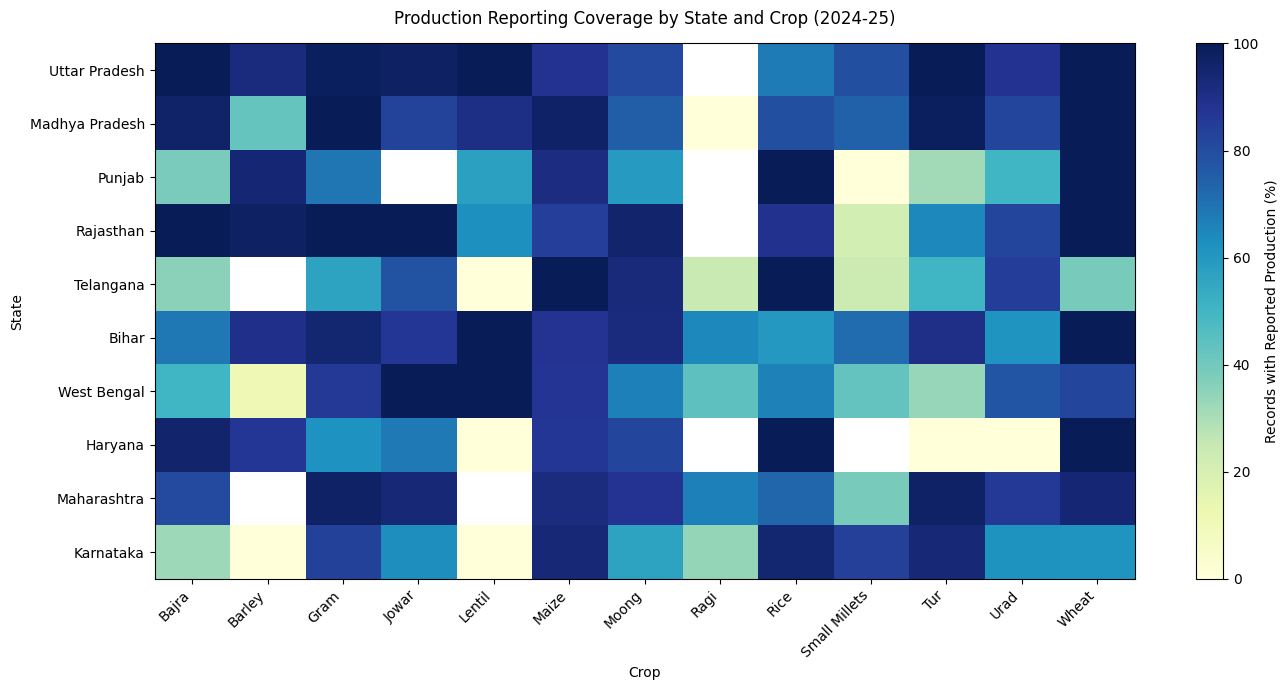

In [23]:

# Calculate production reporting coverage for each state-crop combination.
state_crop_coverage = (
    coverage_df.groupby(["State", "Crop"])
    .agg(
        Total_Records=("Production", "size"),
        Reported_Records=("Production", "count"),
    )
)

state_crop_coverage["Coverage_%"] = (
    state_crop_coverage["Reported_Records"]
    / state_crop_coverage["Total_Records"]
    * 100
)

coverage_matrix = (
    state_crop_coverage["Coverage_%"]
    .unstack("Crop")
)

# Keep the ten states with the largest overall observed production.
selected_states = state_totals.head(10).index

coverage_matrix = coverage_matrix.reindex(selected_states)

fig, ax = plt.subplots(figsize=(14, 7))

image = ax.imshow(
    coverage_matrix,
    aspect="auto",
    interpolation="nearest",
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
)

ax.set_title(
    f"Production Reporting Coverage by State and Crop ({latest_year})",
    pad=14,
)
ax.set_xlabel("Crop")
ax.set_ylabel("State")
ax.set_xticks(range(len(coverage_matrix.columns)))
ax.set_xticklabels(coverage_matrix.columns, rotation=45, ha="right")
ax.set_yticks(range(len(coverage_matrix.index)))
ax.set_yticklabels(coverage_matrix.index)

colorbar = fig.colorbar(image, ax=ax)
colorbar.set_label("Records with Reported Production (%)")

fig.tight_layout()
plt.show()


### Interpretation: Production Reporting Coverage by State and Crop

- Reporting coverage varies substantially across state–crop combinations.
- Several combinations have high reporting coverage, while others contain missing production records.
- A missing production value must not be interpreted as zero production.
- Comparisons between states should account for differences in reporting coverage to avoid misleading conclusions.
- White cells represent combinations with no reported production records in the selected data, rather than confirmed absence of cultivation.

**Limitation:** This chart describes reporting completeness for 2024–25. It does not establish the actual production ranking of states or crops.

## Key Visualization Findings

### 1. Production Patterns
- Rice and wheat contribute substantially to observed production across multiple agricultural years.
- Production patterns differ across states, reflecting variation in crop composition and reported output.
- These comparisons describe reported production, not necessarily complete production totals.

### 2. State and District Differences
- Uttar Pradesh and Madhya Pradesh rank highly in observed production for 2024–25.
- Several of the highest-production districts in the selected records are located in Punjab.
- State and district rankings may be affected by differences in reporting coverage.

### 3. Seasonal Patterns
- Reported production distributions vary across Kharif, Rabi, and Summer records.
- These distributions should not be interpreted as direct comparisons of total seasonal output because the number of reported records differs by season.

### 4. Yield and Area–Production Relationships
- Reported yield distributions vary considerably by crop.
- The relationship between area and production is positive in the observed records, but outliers and inconsistent records remain.
- Yield comparisons require verification of source units and definitions.

### 5. Data Coverage and Quality
- Production reporting coverage varies across crops, states, and years.
- Some data-quality flags increase over time, particularly records with positive yield but no positive area and production.
- Missing observations and suspicious values have not been automatically corrected or removed.

### Conclusion
The visualizations reveal useful patterns in observed crop production, crop composition, yield, and reporting coverage. These findings support further analysis, but reliable prediction requires validating measurement definitions, reviewing anomalous records, and accounting for missing data. Aggregate crop categories must also be handled carefully to prevent double-counting.